<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/18-computer-vision/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: A Recycling Sorter

Sorting rubbish for recycling is slow, dirty work, and mistakes are costly: one greasy pizza box or broken glass bottle in the wrong stream can spoil a whole batch. A camera that tells cardboard from glass from plastic could help a sorting plant, or a smart bin in a school or office.

We'll build the image classifier at the heart of such a system, using **TrashNet**, a dataset collected by Gary Thung and Mindy Yang at Stanford in 2016: 2,527 phone photos of single items of rubbish on a white background, in six classes: **cardboard, glass, metal, paper, plastic** and **trash** (everything that can't be recycled).

That's a small dataset for deep learning, a few hundred photos per class, which makes it a perfect case for **transfer learning**. The plan:

1. Load and look at the photos, and split them into training, validation and test sets.
2. Train a CNN **from scratch**, as a baseline.
3. Use a pretrained ResNet-18 as a **feature extractor**.
4. **Fine-tune** its last stage.
5. Choose on validation, test **once**, and study the mistakes.
6. Save the sorter and wrap it in a function that takes a photo.

The whole notebook runs on a CPU in about five minutes. On Colab you can make it faster with a GPU (Runtime > Change runtime type > GPU); the code uses one automatically if it's there.

## Setup

The photos (a 43 MB zip file) are downloaded from the TrashNet repository on GitHub the first time you run this, and saved in `data/trashnet/`. The pretrained ResNet-18 (about 45 MB) is downloaded by torchvision.

In [1]:
import copy
import io
import time
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

URL = "https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip"
ZIP = Path("data") / "trashnet" / "dataset-resized.zip"
ZIP.parent.mkdir(parents=True, exist_ok=True)
if not ZIP.exists():
    print("downloading TrashNet")
    urllib.request.urlretrieve(URL, ZIP)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "  torchvision", torchvision.__version__, "  running on", device)
_ = torch.manual_seed(0)

PyTorch 2.15.0+cu132   torchvision 0.29.2+cu132   running on cpu


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## 1. The photos

The zip file has one folder per class. The photos are 512 x 384 pixels; we shrink every one to **192 x 144** when loading. That keeps all 2,527 photos in about 200 MB of memory and makes the network's work about four times lighter, while keeping enough detail to tell a bottle from a can.

In [3]:
H, W = 144, 192
start = time.time()
with zipfile.ZipFile(ZIP) as z:
    names = sorted(n for n in z.namelist() if n.startswith("dataset-resized/") and n.endswith(".jpg"))
    CLASSES = sorted({n.split("/")[1] for n in names})
    photos = np.stack([np.asarray(Image.open(io.BytesIO(z.read(n))).convert("RGB").resize((W, H), Image.BILINEAR))
                       for n in names])
labels = np.array([CLASSES.index(n.split("/")[1]) for n in names])
print(f"{len(photos)} photos of shape {photos.shape[1:]}, loaded in {time.time() - start:.0f} seconds")
counts = np.bincount(labels)
for c, name in enumerate(CLASSES):
    print(f"{name:<10} {counts[c]:>4}")

2527 photos of shape (144, 192, 3), loaded in 4 seconds
cardboard   403
glass       501
metal       410
paper       594
plastic     482
trash       137


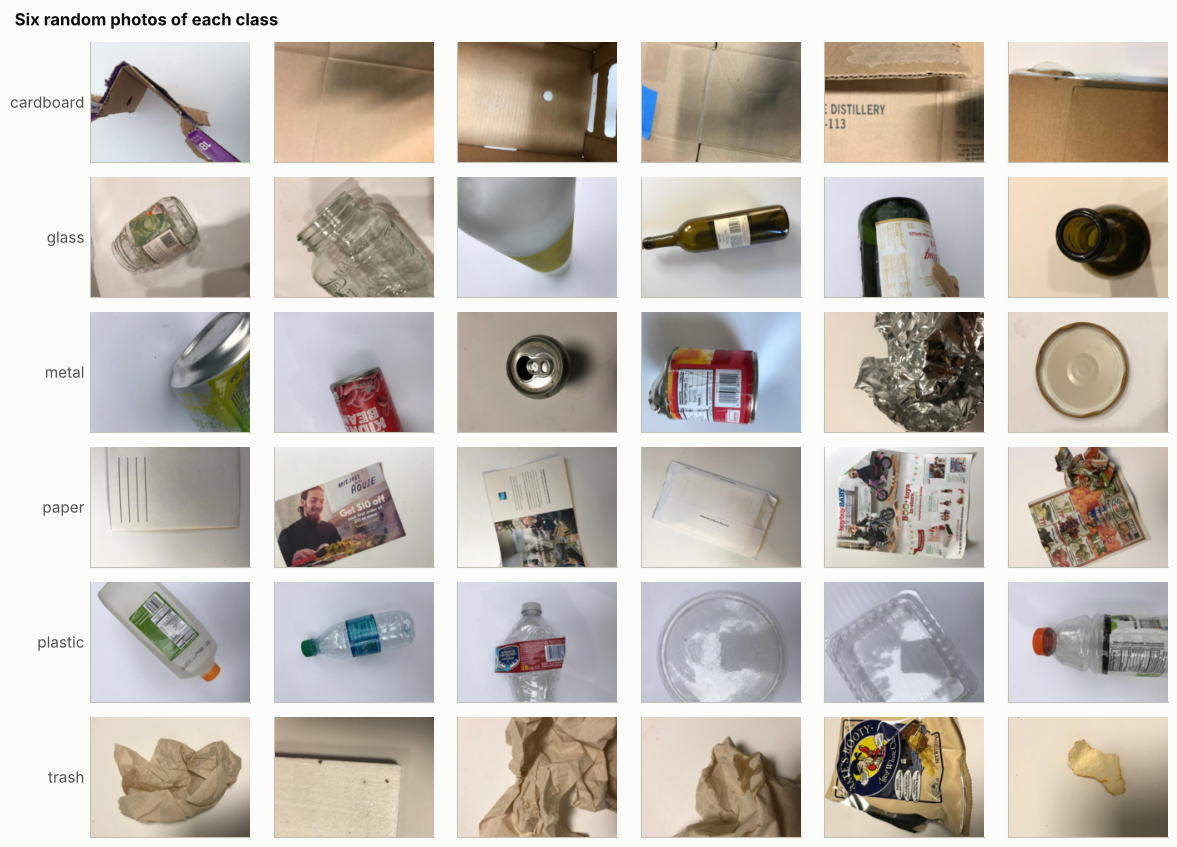

In [4]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(6, 6, figsize=(12, 8.6))
for c, name in enumerate(CLASSES):
    for j, i in enumerate(rng.choice(np.flatnonzero(labels == c), 6, replace=False)):
        ax = axes[c, j]
        ax.imshow(photos[i])
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    axes[c, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=11)
fig.suptitle("Six random photos of each class", x=0.02, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

Most photos show a single item on a white background (many cardboard photos are close-ups of a box instead), so the network doesn't need to find the object, only to say what it's made of. That's still hard: clear plastic bottles look like glass bottles, and crumpled paper looks a lot like the "trash" class (which includes food wrappers and tissues).

The classes are **unbalanced**: there are four times as many paper photos as trash photos. Always guessing "paper" would be right 23.5% of the time, so that's the floor any model has to clear. Accuracy is still a reasonable headline number here, but we'll also look at each class separately.

## 2. Training, validation and test sets

We keep 70% of the photos for training, 15% for validation (to compare models and choose settings) and 15% for testing (used once at the end). The splits are **stratified**, so each set has the same mix of classes (Module 13):

In [5]:
index = np.arange(len(labels))
train_idx, rest = train_test_split(index, test_size=0.3, stratify=labels, random_state=0)
valid_idx, test_idx = train_test_split(rest, test_size=0.5, stratify=labels[rest], random_state=0)
print(f"training {len(train_idx)}, validation {len(valid_idx)}, test {len(test_idx)}")

images = torch.from_numpy(photos).permute(0, 3, 1, 2)                     # (N, 3, 144, 192), uint8
y_all = torch.from_numpy(labels.astype(np.int64))

# ImageNet's channel means and standard deviations: the pretrained network expects them, and they suit our CNN too
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def to_input(x_uint8):
    return (x_uint8.float() / 255 - MEAN.to(x_uint8.device)) / STD.to(x_uint8.device)


def accuracy_of(predictions, idx):
    return float((np.asarray(predictions) == labels[idx]).mean())

training 1768, validation 379, test 380


## 3. A CNN from scratch

First, the approach from the lesson: a small CNN, trained only on our 1,768 training photos. To keep the training time reasonable on a CPU, it works on photos shrunk further, to 64 x 48. Each block halves the image and doubles the channels; global average pooling at the end turns the final feature maps into one number per channel, whatever the image size.

With so few photos, **data augmentation** is essential. Real photos of rubbish will be taken from different distances and angles, so each training photo is randomly mirrored and randomly cropped to between 70% and 100% of its area, then resized back.

In [6]:
small = F.interpolate(images.float(), size=(48, 64), mode="bilinear", antialias=True, align_corners=False).round().to(torch.uint8)

augment = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomResizedCrop((48, 64), scale=(0.7, 1.0), ratio=(1.2, 1.45), antialias=True),
])


class Photos(Dataset):
    def __init__(self, pixels, idx, transform=None):
        self.pixels, self.idx, self.transform = pixels, idx, transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        x = self.pixels[self.idx[i]]
        if self.transform is not None:
            x = self.transform(x)
        return to_input(x.unsqueeze(0))[0], y_all[self.idx[i]]


def conv_block(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]


torch.manual_seed(0)
scratch = nn.Sequential(*conv_block(3, 32), *conv_block(32, 64), *conv_block(64, 128), *conv_block(128, 128),
                        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 6)).to(device)
print(f"parameters: {sum(p.numel() for p in scratch.parameters()):,}")


@torch.no_grad()
def predict(model, X, batch_size=200):
    model.eval()
    return torch.cat([model(X[i:i + batch_size].to(device)).softmax(dim=1).cpu() for i in range(0, len(X), batch_size)])


epochs = 20
train_loader = DataLoader(Photos(small, train_idx, augment), batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(0))
optimizer = torch.optim.AdamW(scratch.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=3e-3, epochs=epochs, steps_per_epoch=len(train_loader))
X_valid_small = to_input(small[valid_idx])

start = time.time()
for epoch in range(epochs):
    scratch.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        F.cross_entropy(scratch(xb), yb).backward()
        optimizer.step()
        scheduler.step()
    if (epoch + 1) % 5 == 0:
        acc = accuracy_of(predict(scratch, X_valid_small).argmax(dim=1), valid_idx)
        print(f"epoch {epoch + 1:>2}: validation accuracy {acc:.3f}   ({time.time() - start:.0f} s)")
scratch_valid = acc

parameters: 241,958


epoch  5: validation accuracy 0.433   (26 s)


epoch 10: validation accuracy 0.625   (52 s)


epoch 15: validation accuracy 0.747   (75 s)


epoch 20: validation accuracy 0.768   (99 s)


Far better than guessing, but not yet a sorter you'd trust: it still gets roughly a quarter of the validation photos wrong. A CNN trained from scratch has to learn everything, from what an edge is to what makes glass look like glass, out of fewer than 2,000 photos. More epochs, larger images and more augmentation would help, but each of those costs a lot more computing time.

## 4. Pretrained features

Now ResNet-18, pretrained on 1.3 million ImageNet photos. ImageNet has no "cardboard" or "trash" classes, but it has bottles, cans, cartons, paper towels and plastic bags, and the network's features describe shapes, textures and materials that should transfer well.

We give it our 192 x 144 photos directly, rather than the 224 x 224 central crop used in ImageNet training: the global average pooling at the end of ResNet works with any image size, and keeping the whole photo means the item is never cropped off. The pixels are scaled with ImageNet's means and standard deviations, as the network expects.

To save time, we pass every photo through the frozen early layers **once** and store the result. We stop after the third stage (`layer3`), for a reason that will become clear in Section 5. For the training photos, we also store the result for a mirrored copy, a cheap form of augmentation.

In [7]:
weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
resnet = torchvision.models.resnet18(weights=weights).to(device).eval()
early_layers = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool, resnet.layer1, resnet.layer2, resnet.layer3)


@torch.no_grad()
def run_early_layers(idx, mirror=False, batch_size=100):
    out = []
    for i in range(0, len(idx), batch_size):
        x = to_input(images[idx[i:i + batch_size]].to(device))
        if mirror:
            x = x.flip(dims=[3])
        out.append(early_layers(x))
    return torch.cat(out)


start = time.time()
L3_train, L3_train_mirrored = run_early_layers(train_idx), run_early_layers(train_idx, mirror=True)
L3_valid, L3_test = run_early_layers(valid_idx), run_early_layers(test_idx)
print(f"stored layer3 outputs of shape {tuple(L3_train.shape[1:])} for {len(L3_train) * 2 + len(L3_valid) + len(L3_test):,} photos "
      f"in {time.time() - start:.0f} seconds")

stored layer3 outputs of shape (256, 9, 12) for 4,295 photos in 38 seconds


Each photo is now 256 feature maps of 9 x 12. Running the rest of the network (`layer4` and the global average pooling) turns them into **512 features** per photo, and on those we train a plain logistic regression (Module 12). This is **feature extraction**: none of ResNet's weights change. The regularisation strength `C` is chosen on the validation set.

In [8]:
@torch.no_grad()
def pooled_features(L3, layer4):
    layer4.eval()
    return torch.cat([resnet.avgpool(layer4(L3[i:i + 200])).flatten(1).cpu() for i in range(0, len(L3), 200)]).numpy()


start = time.time()
features_train = np.concatenate([pooled_features(L3_train, resnet.layer4), pooled_features(L3_train_mirrored, resnet.layer4)])
features_valid = pooled_features(L3_valid, resnet.layer4)
labels_train = np.concatenate([labels[train_idx], labels[train_idx]])

fitted = {}
for C in [0.03, 0.1, 0.3, 1.0]:
    fitted[C] = LogisticRegression(C=C, max_iter=3000).fit(features_train, labels_train)
    print(f"C = {C:<5} validation accuracy {fitted[C].score(features_valid, labels[valid_idx]):.3f}")
best_C = max(fitted, key=lambda C: fitted[C].score(features_valid, labels[valid_idx]))
extractor_valid = fitted[best_C].score(features_valid, labels[valid_idx])
print(f"\nchosen C = {best_C}: validation accuracy {extractor_valid:.3f}   ({time.time() - start:.0f} s)")

C = 0.03  validation accuracy 0.821


C = 0.1   validation accuracy 0.826


C = 0.3   validation accuracy 0.821


C = 1.0   validation accuracy 0.802

chosen C = 0.1: validation accuracy 0.826   (11 s)


A clear step up from the CNN trained from scratch, and the only thing trained here was a linear model on 512 numbers, in a few seconds. The features learnt from ImageNet photos already separate most of our classes.

## 5. Fine-tuning the last stage

Feature extraction keeps ResNet's features exactly as they were learnt for ImageNet. **Fine-tuning** lets some of them adapt to our task. With so little data, we fine-tune only the **last stage** (`layer4`), whose features are the most specific to ImageNet's classes, and keep the general-purpose early layers frozen. That's why we stored the `layer3` outputs: fine-tuning `layer4` only needs to start from there, so each epoch is much faster than running the whole network.

Two settings follow the lesson's advice. The pretrained `layer4` gets a **learning rate ten times smaller** than the new final layer, so its useful features are adjusted rather than overwritten. And we keep the weights from the epoch with the best validation accuracy.

In [9]:
torch.manual_seed(0)
head = nn.Sequential(copy.deepcopy(resnet.layer4), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(512, 6)).to(device)
optimizer = torch.optim.AdamW([
    {"params": head[0].parameters(), "lr": 1e-4},            # pretrained layer4: small steps
    {"params": head[4].parameters(), "lr": 1e-3},            # new final layer: larger steps
], weight_decay=1e-4)

L3_fit = torch.cat([L3_train, L3_train_mirrored])
y_fit = torch.cat([y_all[train_idx], y_all[train_idx]]).to(device)
generator = torch.Generator().manual_seed(0)

best_acc, best_state, start = 0.0, None, time.time()
for epoch in range(5):
    head.train()
    order = torch.randperm(len(L3_fit), generator=generator)
    for i in range(0, len(order), 64):
        batch = order[i:i + 64].to(device)
        optimizer.zero_grad()
        F.cross_entropy(head(L3_fit[batch]), y_fit[batch]).backward()
        optimizer.step()
    acc = accuracy_of(predict(head, L3_valid).argmax(dim=1), valid_idx)
    if acc > best_acc:
        best_acc, best_state = acc, copy.deepcopy(head.state_dict())
    print(f"epoch {epoch + 1}: validation accuracy {acc:.3f}   ({time.time() - start:.0f} s)")
head.load_state_dict(best_state)
finetuned_valid = best_acc

epoch 1: validation accuracy 0.844   (27 s)


epoch 2: validation accuracy 0.876   (54 s)


epoch 3: validation accuracy 0.894   (82 s)


epoch 4: validation accuracy 0.889   (111 s)


epoch 5: validation accuracy 0.887   (146 s)


Fine-tuning adds several more points on top of feature extraction, after only a few epochs. Here are the three approaches side by side:

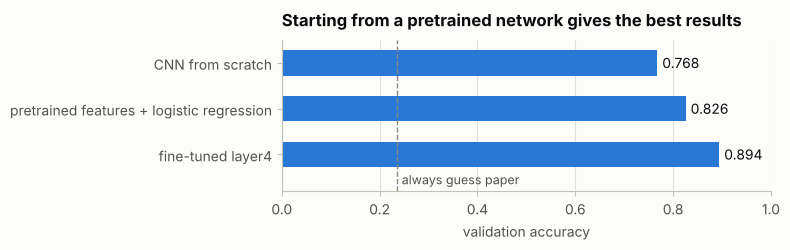

In [10]:
results = {"CNN from scratch": scratch_valid, "pretrained features + logistic regression": extractor_valid,
           "fine-tuned layer4": finetuned_valid}
fig, ax = plt.subplots(figsize=(8, 2.6))
bars = ax.barh(list(results)[::-1], list(results.values())[::-1], color=PALETTE[0], height=0.55)
ax.axvline(counts.max() / counts.sum(), color=MUTED, linestyle="--", linewidth=1)
ax.text(counts.max() / counts.sum() + 0.01, -0.55, "always guess paper", color=INK_2, fontsize=9, va="center")
for bar, value in zip(bars, list(results.values())[::-1]):
    ax.text(value + 0.01, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center", fontsize=10, color=INK)
ax.set_xlim(0, 1)
ax.set_ylim(-0.8, 2.5)
ax.set_xlabel("validation accuracy")
ax.grid(axis="y", visible=False)
ax.set_title("Starting from a pretrained network gives the best results")
plt.tight_layout()
plt.show()

The fine-tuned network is the clear choice. Note that the comparison isn't entirely about the method: the CNN from scratch saw much smaller images. But that's the real trade-off on a CPU. Giving the scratch CNN the same images and enough epochs to compete would take far longer, and it would still be learning from 1,768 photos, while the pretrained network brings what it learnt from more than a million.

## 6. The test set

Only now do we use the test photos, once, with the model chosen on validation:

test accuracy: 0.863   (validation was 0.894)


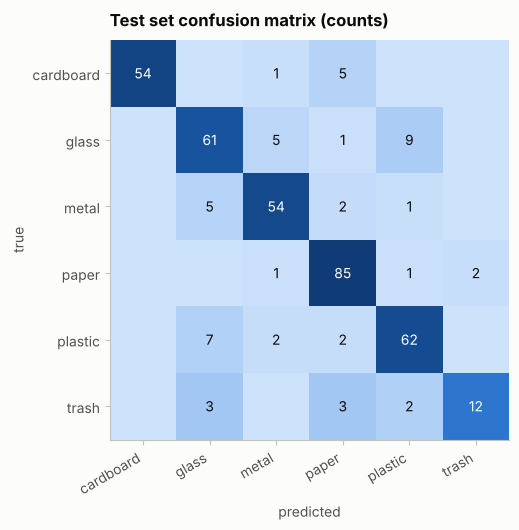

class      test photos   recall  precision
cardboard           60     0.90       1.00
glass               76     0.80       0.80
metal               62     0.87       0.86
paper               89     0.96       0.87
plastic             73     0.85       0.83
trash               20     0.60       0.86


In [11]:
test_probabilities = predict(head, L3_test)
test_predicted = test_probabilities.argmax(dim=1).numpy()
test_truth = labels[test_idx]
print(f"test accuracy: {accuracy_of(test_predicted, test_idx):.3f}   (validation was {finetuned_valid:.3f})")

confusion = np.zeros((6, 6), dtype=int)
np.add.at(confusion, (test_truth, test_predicted), 1)
rates = confusion / confusion.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.imshow(rates, cmap="course_blues", vmin=0, vmax=1)
for i in range(6):
    for j in range(6):
        if confusion[i, j] > 0:
            ax.text(j, i, confusion[i, j], ha="center", va="center", fontsize=10,
                    color="white" if rates[i, j] > 0.5 else INK)
ax.set_xticks(range(6), CLASSES, rotation=30, ha="right")
ax.set_yticks(range(6), CLASSES)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.grid(False)
ax.set_title("Test set confusion matrix (counts)")
plt.tight_layout()
plt.show()

print(f"{'class':<10}{'test photos':>12}{'recall':>9}{'precision':>11}")
for c, name in enumerate(CLASSES):
    recall = confusion[c, c] / confusion[c].sum()
    precision = confusion[c, c] / max(confusion[:, c].sum(), 1)
    print(f"{name:<10}{confusion[c].sum():>12}{recall:>9.2f}{precision:>11.2f}")

The test accuracy is a little lower than the validation accuracy, which is normal for two reasons. We chose the epoch with the best validation score, so that score is slightly optimistic: some of its advantage was luck. And with only 380 test photos, chance alone moves the test accuracy by a couple of points either way (Module 13's bootstrap would put a number on that). The test accuracy is the honest estimate to report.

The table shows **recall** (of the photos that really are this class, how many were recognised) and **precision** (of the photos predicted as this class, how many really are), from Module 13. The **trash** class is the weakest: it has the fewest training photos, and it's a mixed bag by definition, anything that isn't one of the five recyclable materials. Most other confusions are between materials that really do look alike in a photo.

Let's look at some mistakes:

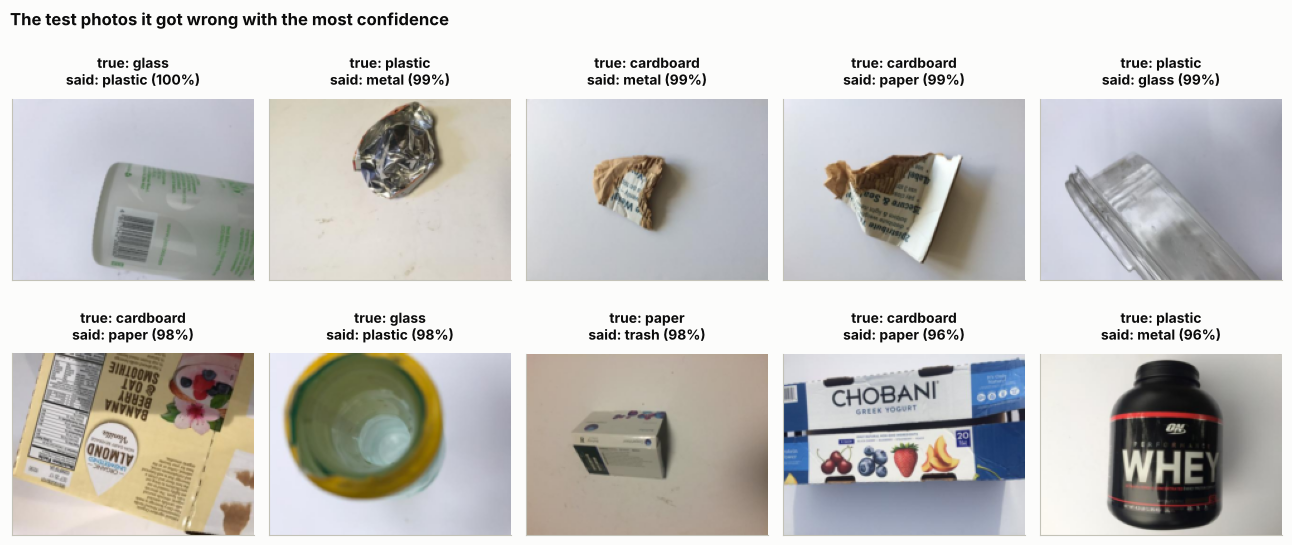

52 of 380 test photos misclassified


In [12]:
wrong = np.flatnonzero(test_predicted != test_truth)
confidence = test_probabilities.max(dim=1).values.numpy()
show = wrong[np.argsort(-confidence[wrong])][:10]

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, k in zip(axes.flat, show):
    ax.imshow(photos[test_idx[k]])
    ax.set_title(f"true: {CLASSES[test_truth[k]]}\nsaid: {CLASSES[test_predicted[k]]} ({confidence[k]:.0%})", fontsize=10, loc="center")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
for ax in axes.flat[len(show):]:
    ax.axis("off")
fig.suptitle("The test photos it got wrong with the most confidence", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()
print(f"{len(wrong)} of {len(test_idx)} test photos misclassified")

Looking at these is the most useful thing you can do with a classifier. Most of the mistakes are understandable: clear plastic and glass look alike, thin printed cardboard looks a lot like paper, and shiny packaging can look like metal. Some are arguably labelling questions (is a crumpled, shiny wrapper plastic or metal?), which every dataset has.

For a real sorting plant, the numbers above would be only the start. You'd want photos taken on the plant's own conveyor belt, in its lighting, of items that are dirty, crushed and overlapping, because a model trained on clean single items on white posterboard may do much worse there. That's **distribution shift** (Module 21 returns to it), and the only real defence is to test on data that looks like the real use.

## 7. Saving the sorter

To use the sorter elsewhere, we put the pieces back into one ordinary ResNet-18: the pretrained early layers, the fine-tuned `layer4`, and a new final layer. Then the whole model can be saved as one state dict and loaded into `torchvision.models.resnet18` with six outputs.

In [13]:
sorter = torchvision.models.resnet18(weights=weights)
sorter.layer4 = copy.deepcopy(head[0])
sorter.fc = copy.deepcopy(head[4])
sorter = sorter.eval().cpu()

Path("work").mkdir(exist_ok=True)
torch.save({"state_dict": sorter.state_dict(), "classes": CLASSES, "size": (H, W)}, "work/recycling_sorter.pt")
print(f"saved: {Path('work/recycling_sorter.pt').stat().st_size / 1e6:.0f} MB")

saved = torch.load("work/recycling_sorter.pt", weights_only=True)
loaded = torchvision.models.resnet18(weights=None, num_classes=len(saved["classes"]))
loaded.load_state_dict(saved["state_dict"])
loaded.eval()


@torch.no_grad()
def sort_item(photo, model=loaded, info=saved):
    """Classify one photo (a PIL image or a NumPy array). Returns (class, confidence)."""
    image = Image.fromarray(np.asarray(photo)).convert("RGB").resize(info["size"][::-1], Image.BILINEAR)
    x = torch.from_numpy(np.asarray(image).copy()).permute(2, 0, 1).unsqueeze(0)
    probabilities = model(to_input(x)).softmax(dim=1)[0]
    p, c = probabilities.max(dim=0)
    return info["classes"][c.item()], p.item()


with zipfile.ZipFile(ZIP) as z:
    for k in range(4):
        name = names[test_idx[k]]
        original = Image.open(io.BytesIO(z.read(name)))               # the full-size 512 x 384 photo
        prediction, p = sort_item(original)
        print(f"{name.split('/')[-1]:<16} predicted {prediction:<10} ({p:.0%})   true: {CLASSES[test_truth[k]]}")

loaded_predictions = predict(loaded.to(device), to_input(images[test_idx])).argmax(dim=1).numpy()
print(f"\nthe loaded model's test accuracy: {accuracy_of(loaded_predictions, test_idx):.3f}")

saved: 45 MB


metal370.jpg     predicted glass      (51%)   true: metal
metal252.jpg     predicted metal      (100%)   true: metal
plastic124.jpg   predicted plastic    (100%)   true: plastic
paper345.jpg     predicted paper      (100%)   true: paper



the loaded model's test accuracy: 0.863


`sort_item` takes a photo at its original size, exactly as it would arrive from a camera, and does the resizing and scaling itself. The loaded model reproduces the test accuracy, so the pieces were put back together correctly.

## What we learned

- **A small dataset doesn't mean no deep learning.** With 1,768 training photos, a CNN from scratch was mediocre, while a network pretrained on ImageNet was far ahead.
- **Feature extraction** (frozen network, simple classifier on top) is fast and already very good.
- **Fine-tuning the last stage**, with a smaller learning rate for the pretrained layers, adapts the features to the task and adds several more points.
- **Storing the outputs of frozen layers** makes fine-tuning on a CPU practical.
- **Choose on validation, test once,** and remember that a test set of a few hundred photos gives an estimate, not an exact number.
- **The weakest class is the smallest and most varied one.** More photos of it would be the best next step.

**Try next:**

- Fine-tune `layer3` as well (you'll need to store `layer2` outputs instead). Does it help, or does it start to overfit?
- Add class weights to the loss (`F.cross_entropy(..., weight=...)`) to make the network pay more attention to the trash class. What happens to its recall, and to the other classes' precision?
- Photograph a few items of your own rubbish on a white sheet of paper and try `sort_item` on them. How well does it cope with your camera and your lighting?

The pretrained features here came from a network that only ever saw images. In Module 19 we turn to sequences and text, and build the attention mechanism behind transformers, which now power models for language, images and much more.